# Vectors From Columns

**Version**: 1

**Last modified**: 2026-10-12

**Compatible with opengate-gate-tree version:** 0.6.0

**Author**: Mateusz Jakub Bała

## About

A "Hits" tree carries vectors as three columns side by side: `posX, posY, posZ`
for where a hit happened, `momDirX, momDirY, momDirZ` for where the particle
went afterwards. This notebook reads such triples as the vectors they are, and
asks them geometric questions: how far a hit is from the source, at what angle
a gamma scattered, where a hit lies along the axis and across it, and in which
direction it is seen from the source.

It is also about the one rule that keeps vector arithmetic honest: two sets of
vectors combine only when they describe the same rows.

## What will you learn from this notebook

- how to read three columns of a frame as a column of vectors
- what shape an answer takes: a number per row, a vector per row, or three
  numbers per row
- how to measure lengths and angles, and split a vector along an axis and
  across it
- how to read a vector in spherical components, and which angle is which
- why combining vectors of different rows is refused, and how to pair rows
  properly
- how to do the same on plain `(N, 3)` arrays

## Theory

The length of a vector is its norm, and its direction is what is left when the
length is divided out:

$$
\lVert v \rVert = \sqrt{v_x^2 + v_y^2 + v_z^2},
\qquad
\hat{v} = \frac{v}{\lVert v \rVert}
$$

The angle between two directions, in $[0, \pi]$, is computed through both
products, which keeps it exact at both ends of the range:

$$
\theta = \operatorname{atan2}
\left(\lVert \hat{u}\times\hat{v} \rVert,\ \hat{u}\cdot\hat{v}\right)
= \arccos\left(\hat{u}\cdot\hat{v}\right)
$$

A vector splits into the part along a direction $\hat{a}$ and the part across
it:

$$
v_\parallel = \left(\hat{a}\cdot v\right)\hat{a},
\qquad
v_\perp = v - v_\parallel
$$

and in spherical components into a radius, a polar angle measured from the
$z$ axis, and an azimuth measured around it from $x$ towards $y$:

$$
r = \lVert v \rVert,
\qquad
\theta_{\text{polar}} = \arccos\left(\frac{v_z}{r}\right) \in [0, \pi],
\qquad
\varphi_{\text{azimuth}} = \operatorname{atan2}(v_y, v_x) \in [0, 2\pi)
$$

## Tutorial

Every step below is a line of text, the code that does what the line says, and
a word about the answer where the answer needs one.

In [1]:
from tools import environment, paths, plotting

plotting.use_tutorial_style()
print(environment.describe())

opengate-gate-tree: 0.5.0
python: 3.14.5
run on: 2026-10-12


The header of this notebook states the version it was written for; the line
above states the version it just ran against. If they differ, the notebook may
still be right — but nobody has checked it against what is installed.

The example file this notebook reads is a small GATE output carried in the
repository; what it holds is described in
[`../data/README.md`](../data/README.md). Nothing is written, so no output
directory is needed.

In [2]:
import numpy as np

from opengate_gate_tree import (
    GateTree,
    angle_between,
    as_vectors,
    norm,
    read_tree,
)

example_input = paths.input_example("positronium-source-all-variants.root")
frame = read_tree(example_input, GateTree.HITS).to_dataframe()

### Reading Vectors Out Of A Frame

Four triples of a "Hits" tree have a method of their own on the `gate`
namespace: `position()`, `local_position()`, `source_position()` and
`momentum_direction()`. Any other three columns are read with
`vector("aX", "aY", "aZ")`.

In [3]:
position = frame.gate.position()
position

VectorView(500 vectors, names=('posX', 'posY', 'posZ'))

A `VectorView` holds the values as an `(N, 3)` array and the index of the rows
they came from. The array is `float64`, although the file holds `float32`, and
it is read-only — a view owns nothing and never writes back into the frame:

In [4]:
frame["posX"].dtype, position.array.dtype, position.array.shape, position.array.flags.writeable

(dtype('float32'), dtype('float64'), (500, 3), False)

### What An Answer Looks Like

The shape of the answer follows the shape of the question. A number per row —
a length — comes back as a column, with the index of the rows:

In [5]:
distance = position.norm()
distance.describe()

count    500.000000
mean     207.180519
std        8.122091
min      200.002435
25%      201.569968
50%      204.800122
75%      210.358603
max      263.507327
Name: norm, dtype: float64

The source of this scene sits at the origin — every `sourcePos` value is zero —
so the norm of a position is the distance of the hit from the source:

In [6]:
frame[["sourcePosX", "sourcePosY", "sourcePosZ"]].abs().max()

sourcePosX    0.0
sourcePosY    0.0
sourcePosZ    0.0
dtype: float32

No hit is closer than 200 mm, which is where the inside of the spherical shell
of this detector begins.

A vector per row comes back as another view, and three numbers per row as a
frame:

In [7]:
position.unit(), type(position.spherical()).__name__

(VectorView(500 vectors, names=('posX', 'posY', 'posZ')), 'DataFrame')

### The Direction Of Flight

Where a gamma went from the source to its hit is one position minus the other.
The difference is a view again; its components are called `x`, `y`, `z`,
because it no longer describes the columns it was read from:

In [8]:
flight = position - frame.gate.source_position()
flight.names

('x', 'y', 'z')

Which hits are the first of their track? The hits of one track share
`(runID, eventID, trackID)`, and in this file they follow one another in the
order they happened — `time` grows within every track — so counting within each
track numbers them:

In [9]:
frame["hitIndex"] = frame.groupby(["runID", "eventID", "trackID"]).cumcount()
frame["hitIndex"].value_counts().sort_index()

hitIndex
0    311
1    130
2     44
3     13
4      2
Name: count, dtype: int64

### The Angle At The First Hit

`momDir` is where the particle went **after** the hit. At the first hit of a
track, the gamma arrived straight from the source, so the angle between the
direction of flight and `momDir` is how much the hit turned it. Angles are in
radians; `rad_to_deg` reads them in degrees:

In [10]:
first = frame[frame["hitIndex"] == 0]

turn = (
    (first.gate.position() - first.gate.source_position())
    .angle_to(first.gate.momentum_direction())
    .gate.rad_to_deg()
)
turn.groupby(first["processName"]).describe()

,count,mean,std,min,25%,50%,75%,max
processName,,,,,,,,
Compton,131.0,63.970047,3.928344e+01,2.462726e+00,3.547573e+01,5.407375e+01,90.402458,167.353289
PhotoElectric,180.0,0.000001,7.553282e-07,2.267587e-08,4.620693e-07,8.138435e-07,0.000002,0.000004


Two answers, one per process. At a photoelectric hit the angle is a few
millionths of a degree: the gamma ends there, and `momDir` keeps the direction
it arrived in. At a Compton hit the gamma goes on in a new direction, and the
angle is the Compton scattering angle:

<Axes: title={'center': 'Compton scattering at the first hit of a track'}, xlabel='scattering angle [deg]', ylabel='counts / 10 deg'>

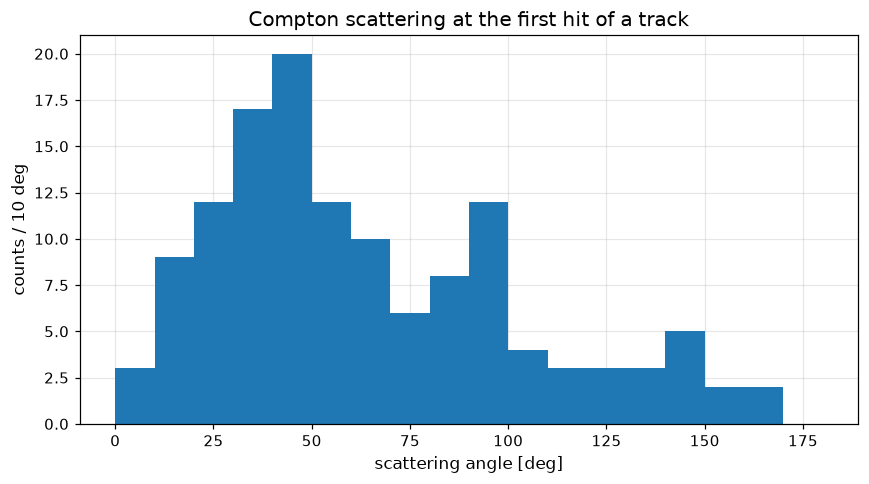

In [11]:
plotting.plot_hist_1d(
    turn[first["processName"] == "Compton"],
    xrange=(0.0, 180.0),
    xbins=18,
    xtitle="scattering angle [deg]",
    ytitle="counts / 10 deg",
    title="Compton scattering at the first hit of a track",
)

### Two Views Combine Only For The Same Rows

The step from the first hit of a track to its second is the second position
minus the first. Taken from two selections, it is refused:

In [12]:
second = frame[frame["hitIndex"] == 1]

try:
    second.gate.position() - first.gate.position()
except ValueError as error:
    print(error)

Two views are combined row by row, so they describe the same rows: got 130 row(s) against 311, with different index values. Select the rows first, then read the vectors.


That is the point of the rule. Vectors of different rows would be zipped by
position — the first of 311 first hits with the first of 130 second hits, which
belong to different tracks. Plain arrays do exactly that, as soon as their
lengths happen to agree, and say nothing:

In [13]:
columns = ["posX", "posY", "posZ"]
silently_wrong = second[columns].to_numpy() - first[columns].to_numpy()[: len(second)]
silently_wrong.shape

(130, 3)

The right way is to put the two hits of a track on one row first, by the track
they belong to, and then read the vectors from that row with `vector()`:

In [14]:
pairs = first.merge(second, on=["runID", "eventID", "trackID"], suffixes=("_1", "_2"))

first_hit = pairs.gate.vector("posX_1", "posY_1", "posZ_1")
second_hit = pairs.gate.vector("posX_2", "posY_2", "posZ_2")
direction_after_first = pairs.gate.vector("momDirX_1", "momDirY_1", "momDirZ_1")

step = second_hit - first_hit
len(pairs)

130

130 tracks have a second hit. The step from the first hit to the second is the
direction the gamma left the first hit in — which is what `momDir` at the first
hit claims to be. Measured:

In [15]:
direction_after_first.angle_to(step).gate.rad_to_deg().describe()

count    130.000000
mean       0.000792
std        0.002877
min        0.000003
25%        0.000064
50%        0.000149
75%        0.000425
max        0.024878
Name: angle, dtype: float64

They agree to within 0.025°, the largest disagreement among 130 tracks. So
`momDir` at a hit points at the next hit, and the direction a gamma *arrived*
in is not in the file: it has to be rebuilt from positions, as above.

### Products

The scalar product is a number per row, the vector product a vector per row.
The vector product is perpendicular to both of its arguments, so its scalar
product with either one is zero, up to rounding:

In [16]:
momentum = frame.gate.momentum_direction()
normal = position.cross(momentum)

normal.dot(position).abs().max(), normal.dot(momentum).abs().max()

(np.float64(3.637978807091713e-12), np.float64(1.4210854715202004e-14))

Both are zero to within 4·10⁻¹² — next to positions of 200 mm, that is
rounding in `float64`.

### Along An Axis And Across It

A vector splits into the part along a direction and the part across it. Along
the `z` axis, the part along is the `posZ` column and the length of the part
across is the distance from the axis:

In [17]:
along = position.parallel_to([0.0, 0.0, 1.0])
across = position.perpendicular_to([0.0, 0.0, 1.0])

(
    np.allclose(along.z, frame["posZ"]),
    np.allclose(across.norm(), np.hypot(frame["posX"], frame["posY"])),
)

(True, True)

The two parts add back up to the vector they came from, and the length of the
axis does not matter — only where it points:

In [18]:
(
    np.abs((along + across).array - position.array).max(),
    np.allclose(position.parallel_to([0.0, 0.0, 5.0]).array, along.array),
)

(np.float64(0.0), True)

### Spherical Components

`spherical()` answers with three columns: the radius, the polar angle from the
`z` axis in `[0, π]`, and the azimuth around it in `[0, 2π)`. The columns are
named `polar` and `azimuth` rather than `theta` and `phi`, because the two
conventions in circulation swap those names. Seen from the source, the first
hits are spread like this:

In [19]:
directions = first.gate.position().spherical()
directions.describe()

,radius,polar,azimuth
count,311.000000,311.000000,311.000000
mean,205.566177,1.561917,3.075554
std,7.201382,0.706380,1.780315
min,200.002435,0.115355,0.025700
25%,201.023278,1.015581,1.551893
50%,202.746893,1.547748,3.116549
75%,207.552296,2.129572,4.591159
max,251.275010,3.131863,6.271764


For directions spread evenly over a sphere, the cosine of the polar angle and
the azimuth are both spread evenly over their ranges. Drawn for the 311 first
hits:

<Axes: title={'center': 'First hits seen from the source'}, xlabel='cosine of the polar angle', ylabel='counts / 0.2'>

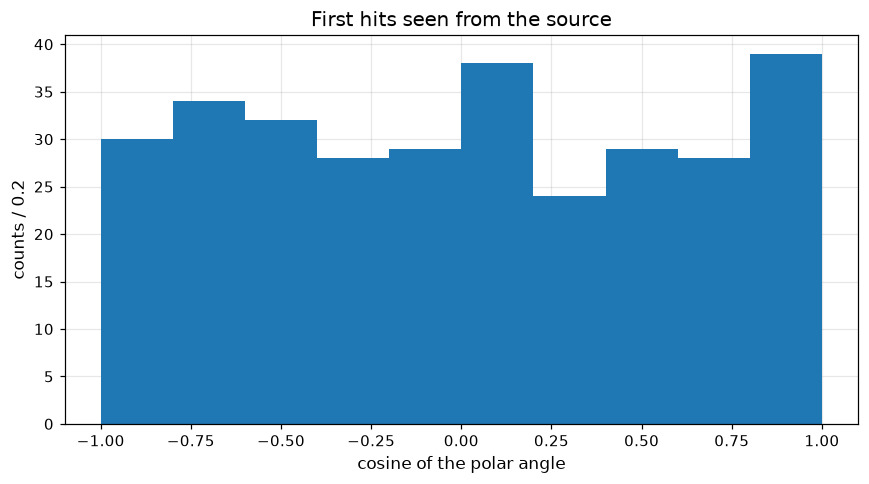

In [20]:
plotting.plot_hist_1d(
    np.cos(directions["polar"]),
    xrange=(-1.0, 1.0),
    xbins=10,
    xtitle="cosine of the polar angle",
    ytitle="counts / 0.2",
    title="First hits seen from the source",
)

<Axes: title={'center': 'First hits seen from the source'}, xlabel='azimuth [rad]', ylabel='counts / (π/4)'>

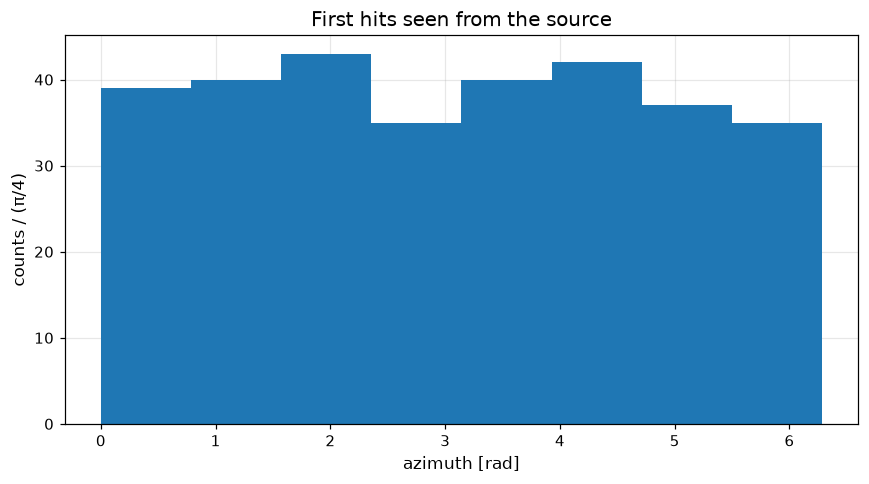

In [21]:
plotting.plot_hist_1d(
    directions["azimuth"],
    xrange=(0.0, 2.0 * np.pi),
    xbins=8,
    xtitle="azimuth [rad]",
    ytitle="counts / (π/4)",
    title="First hits seen from the source",
)

Both are flat within what 311 counts allow: no direction is preferred.

### Back Into The Frame

A view becomes three columns again with `to_frame`, named after a prefix, and
the index it carries puts them back beside the rows they came from:

In [22]:
first.join(first.gate.position().unit().to_frame("dir"))[
    ["eventID", "trackID", "dirX", "dirY", "dirZ"]
].head()

,eventID,trackID,dirX,dirY,dirZ
0,0,2,-0.920199,0.010511,-0.391311
2,0,1,0.920199,-0.010511,0.391311
4,1,2,0.818714,0.378680,0.431636
8,1,1,-0.818714,-0.378680,-0.431636
9,2,3,-0.658951,0.283840,0.696576


Tracks 1 and 2 of event 0, and of event 1, are seen in exactly opposite
directions: the two annihilation gammas of a decay into two, which leave
back to back.

### The Same On Plain Arrays

Every operation of a view is also a function on `(N, 3)` arrays, for code that
works with NumPy rather than frames. `as_vectors` checks the shape, and the
answers are the same:

In [23]:
positions = as_vectors(frame[["posX", "posY", "posZ"]].to_numpy())
directions_after = as_vectors(frame[["momDirX", "momDirY", "momDirZ"]].to_numpy())

(
    np.allclose(norm(positions), position.norm()),
    np.allclose(angle_between(positions, directions_after), position.angle_to(momentum)),
)

(True, True)

A single vector has to be given as one row, `(1, 3)`, not as `(3,)`:

In [24]:
try:
    as_vectors([1.0, 2.0, 3.0])
except ValueError as error:
    print(error)

Vectors are given as an array of shape (N, 3), got shape (3,).


## Summary

Three columns of a frame are read as a `VectorView`, which answers with a
column for a number per row, a view for a vector per row and a frame for three
numbers per row, always with the index of the rows. Two views combine only when
they describe the same rows, so rows that belong together — the hits of one
track — are put on one row first. With that, the distance from the source, the
scattering angle at a hit and the direction it is seen in are a line each.

## Bibliography

- [Vectors And Angles](https://opengate-gate-tree.readthedocs.io/en/latest/guide/vectors.html)
  — every formula used here, the spherical convention and the precision of the
  angle
- [Event Identifiers](https://opengate-gate-tree.readthedocs.io/en/latest/guide/events.html)
  — why a track is `(runID, eventID, trackID)`
- [The "Hits" Tree](https://opengate-gate-tree.readthedocs.io/en/latest/guide/hits.html)
  — the position and momentum branches
- [Units](https://opengate-gate-tree.readthedocs.io/en/latest/guide/units.html)
  — `rad_to_deg`, and why positions are in mm

## Changelog

- v1: written.